### Setup and Library Imports

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

### Data Loading and Initial Inspection

In [2]:
# Load the dataset (dataset is downloaded from https://www.kaggle.com/datasets/iamsouravbanerjee/customer-shopping-trends-dataset?resource=download&select=shopping_trends.csv)
df = pd.read_csv("shopping_trends.csv")

# Preview the data
df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,Cash,2-Day Shipping,No,No,32,Venmo,Weekly
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,PayPal,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Credit Card,Standard,No,No,24,Venmo,Quarterly
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,PayPal,Express,No,No,24,Venmo,Weekly


In [3]:
# Display dataset structure and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   object 
 13  Shipping Type             3900 non-null   object 
 14  Discount

In [4]:
# Check for missing values
df.isnull().sum()

Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64

In [5]:
# Check for duplicate rows
df.duplicated().sum()

0

### Exploratory Data Analysis (EDA)

In [6]:
# Create age groups
bins = [0, 18, 30, 50, 65, 100]
labels = ['<18', '18–30', '30–50', '50–65', '65+']

df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

# Preview updated dataset
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases,Age Group
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly,50–65
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly,18–30
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly,30–50
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly,18–30
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually,30–50


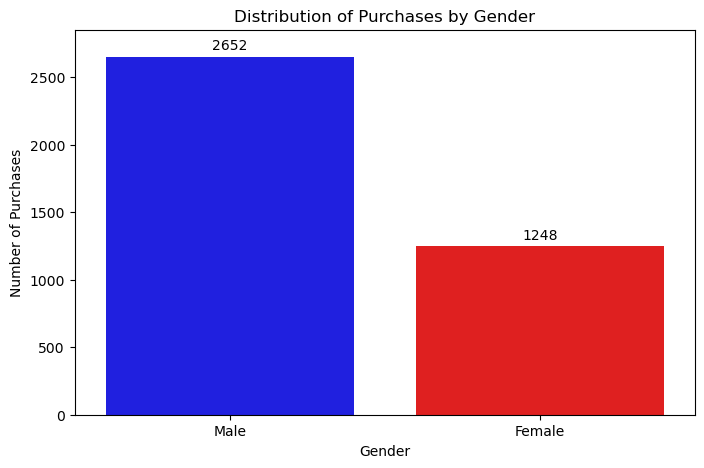

In [7]:
# Gender distribution analysis
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='Gender',
    hue='Gender',
    palette={'Male': 'blue', 'Female': 'red'},
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.title('Distribution of Purchases by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Purchases')
plt.ylim(0, df['Gender'].value_counts().max() + 200)

plt.show()

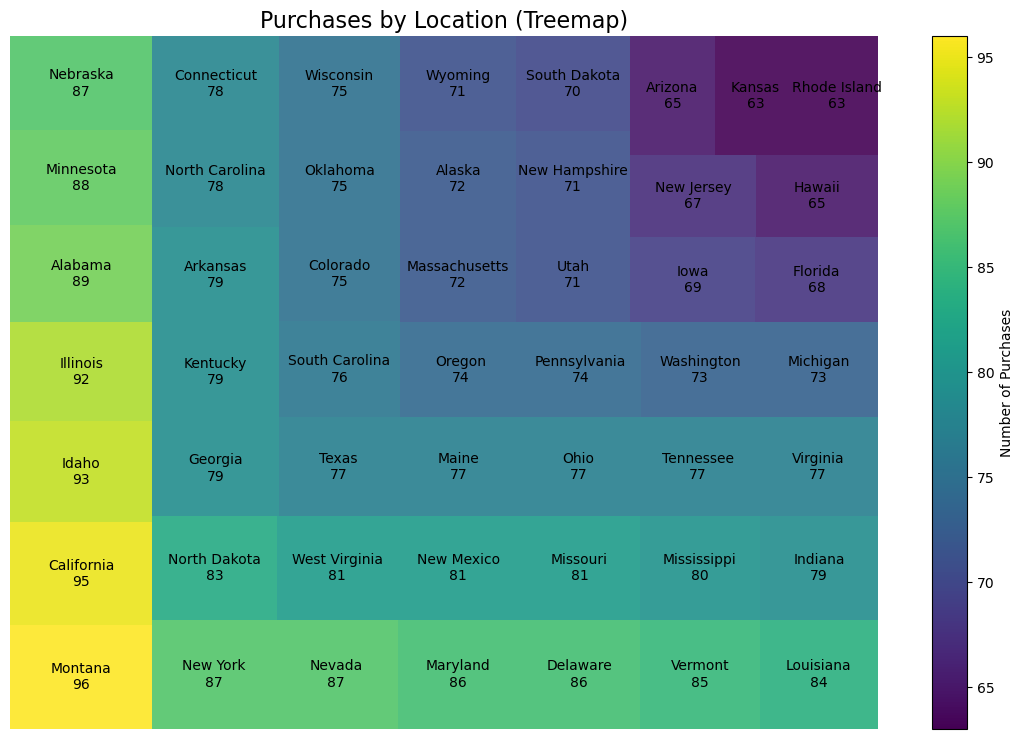

In [8]:
# Location distribution analysis
import squarify
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

location_counts = df['Location'].value_counts().sort_values(ascending=False)
labels = [f"{state}\n{count}" for state, count in zip(location_counts.index, location_counts.values)]

norm = mcolors.Normalize(vmin=location_counts.values.min(), vmax=location_counts.values.max())
cmap = cm.viridis
colors = [cmap(norm(value)) for value in location_counts.values]

fig, ax = plt.subplots(figsize=(14, 9))

squarify.plot(
    sizes=location_counts.values,
    label=labels,
    color=colors,
    alpha=0.9,
    pad=False,
    text_kwargs={'fontsize': 10},
    ax=ax
)

ax.set_title('Purchases by Location (Treemap)', fontsize=16)
ax.axis('off')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Number of Purchases')

plt.show()

In [9]:
# Unique payment methods
print("Available payment methods:", df['Payment Method'].unique())
print("Preferred payment methods:", df['Preferred Payment Method'].unique())

Available payment methods: ['Credit Card' 'Bank Transfer' 'Cash' 'PayPal' 'Venmo' 'Debit Card']
Preferred payment methods: ['Venmo' 'Cash' 'Credit Card' 'PayPal' 'Bank Transfer' 'Debit Card']


In [10]:
# Regroup product categories into broader groups
df['Category'] = df['Category'].replace({
    'Blouse': 'Clothing',
    'Sweater': 'Clothing',
    'Jeans': 'Clothing',
    'Hoodie': 'Clothing',
    'Sandals': 'Footwear',
    'Shoes': 'Footwear',
    'Backpack': 'Accessories',
    'Handbag': 'Accessories',
    'Belt': 'Accessories'
})

# Regroup payment methods into broader groups
df['Payment Method'] = df['Payment Method'].replace({
    'Venmo': 'Digital',
    'PayPal': 'Digital'
})

df['Preferred Payment Method'] = df['Preferred Payment Method'].replace({
    'Venmo': 'Digital',
    'PayPal': 'Digital'
})

# Preview updated data
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases,Age Group
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Digital,Fortnightly,50–65
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly,18–30
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly,30–50
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Digital,Next Day Air,Yes,Yes,49,Digital,Weekly,18–30
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,Digital,Annually,30–50


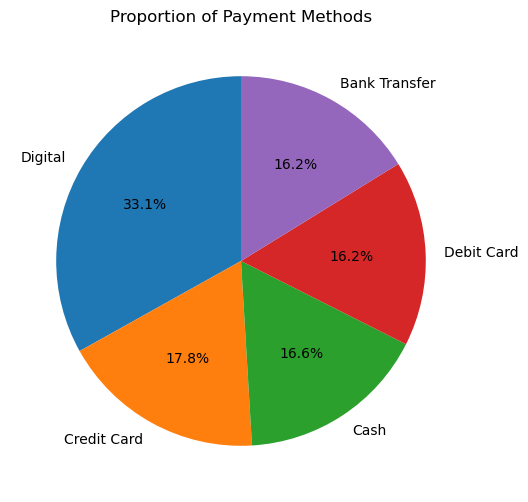

In [11]:
# Payment method distribution
payment_counts = df['Payment Method'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Proportion of Payment Methods')

plt.show()

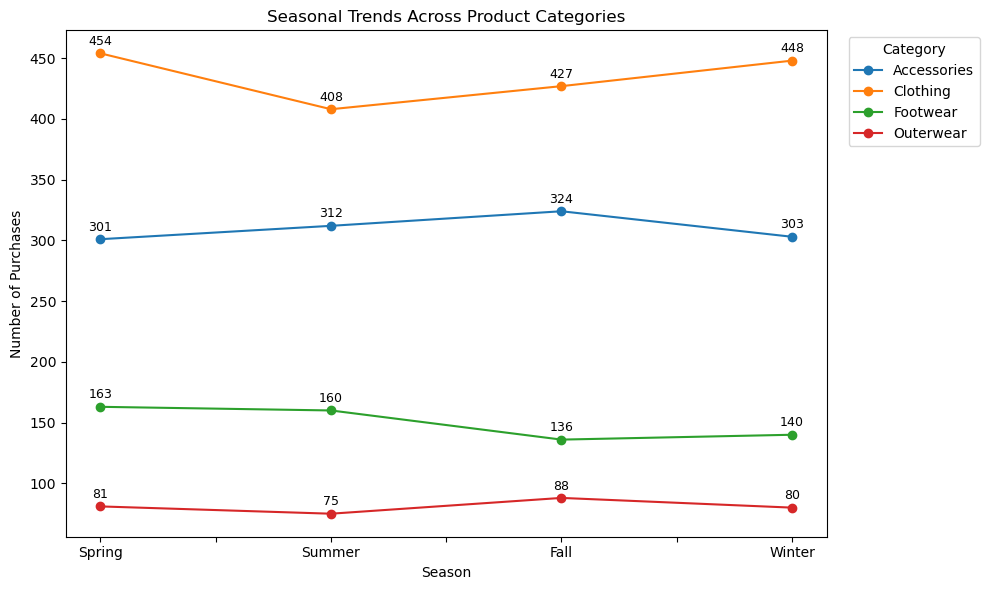

In [12]:
# Group data by category and season
category_season = df.groupby(['Category', 'Season']).size().unstack(fill_value=0)

# Reorder seasons
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
category_season = category_season[season_order]

# Plot line chart
ax = category_season.T.plot(
    marker='o',
    figsize=(10, 6)
)

# Add value labels to each point
for line in ax.lines:
    for x, y in zip(line.get_xdata(), line.get_ydata()):
        ax.annotate(
            f'{int(y)}',
            xy=(x, y),
            xytext=(0, 6),
            textcoords='offset points',
            ha='center',
            fontsize=9
        )

plt.title('Seasonal Trends Across Product Categories')
plt.xlabel('Season')
plt.ylabel('Number of Purchases')
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()

plt.show()

### Correlation Analysis

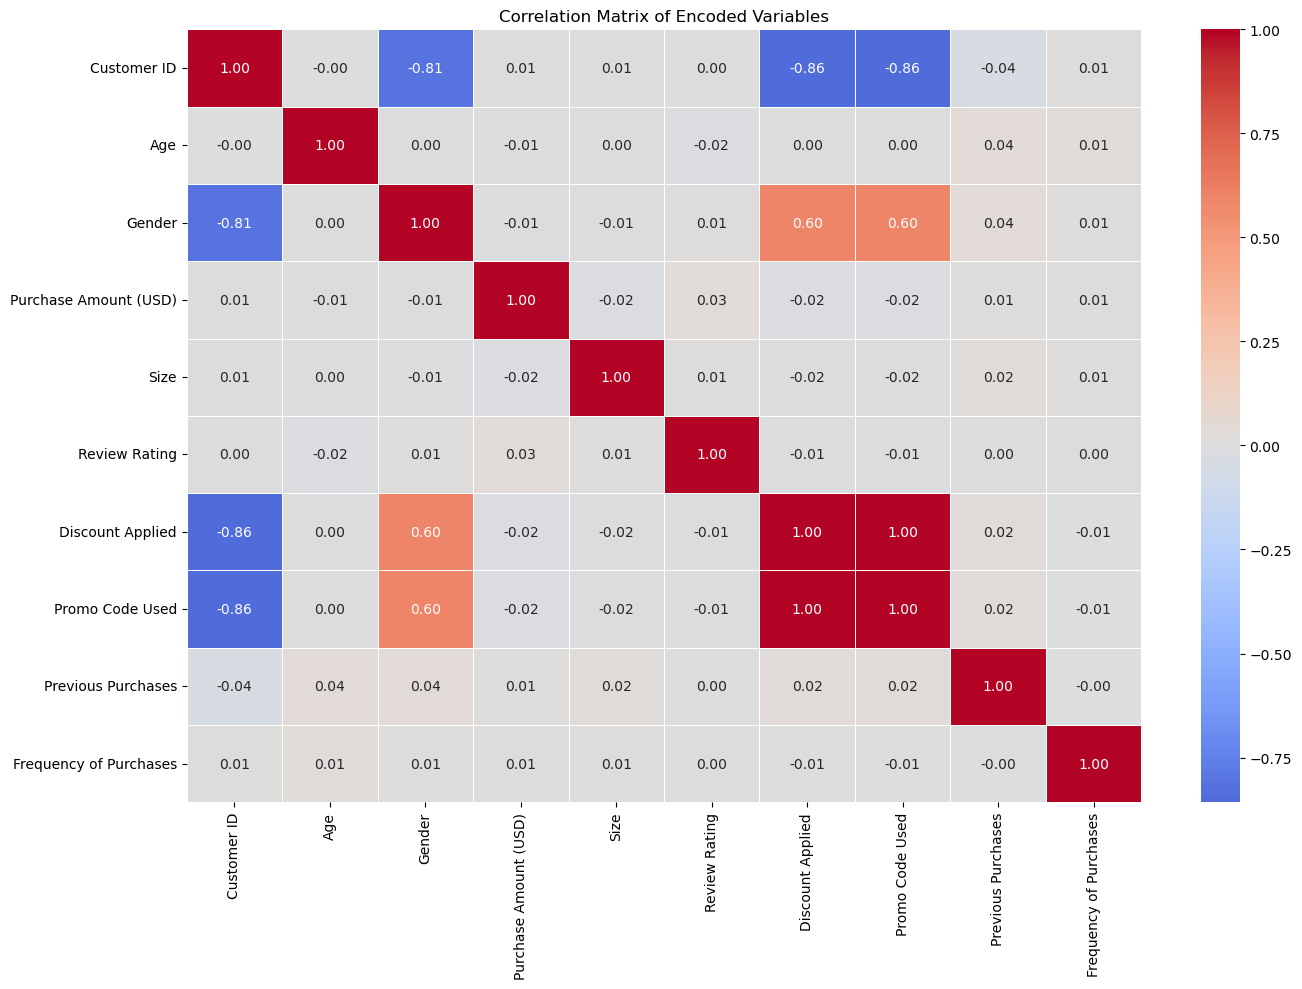

In [13]:
# Create a copy for correlation analysis
df_corr = df.copy()

# Encode binary variables
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df_corr['Gender'] = le.fit_transform(df_corr['Gender'])
df_corr['Discount Applied'] = le.fit_transform(df_corr['Discount Applied'])
df_corr['Promo Code Used'] = le.fit_transform(df_corr['Promo Code Used'])

# Map ordinal categories
size_mapping = {'S': 1, 'M': 2, 'L': 3, 'XL': 4}
df_corr['Size'] = df_corr['Size'].map(size_mapping)

frequency_mapping = {'Weekly': 1, 'Bi-Weekly': 2, 'Monthly': 3, 'Quarterly': 4, 'Annually': 5}
df_corr['Frequency of Purchases'] = df_corr['Frequency of Purchases'].map(frequency_mapping)

# One-hot encode nominal variables
nominal_cols = ['Season', 'Payment Method', 'Category', 'Location']
df_corr = pd.get_dummies(df_corr, columns=nominal_cols, drop_first=True)

# Select numeric columns
numeric_cols = df_corr.select_dtypes(include=['float64', 'int64'])

# Calculate correlation matrix
correlation_matrix = numeric_cols.corr()

# Plot heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Encoded Variables')
plt.tight_layout()
plt.show()

In [14]:
location_counts

Location
Montana           96
California        95
Idaho             93
Illinois          92
Alabama           89
Minnesota         88
Nebraska          87
New York          87
Nevada            87
Maryland          86
Delaware          86
Vermont           85
Louisiana         84
North Dakota      83
West Virginia     81
New Mexico        81
Missouri          81
Mississippi       80
Indiana           79
Georgia           79
Kentucky          79
Arkansas          79
North Carolina    78
Connecticut       78
Texas             77
Maine             77
Ohio              77
Tennessee         77
Virginia          77
South Carolina    76
Colorado          75
Oklahoma          75
Wisconsin         75
Oregon            74
Pennsylvania      74
Washington        73
Michigan          73
Massachusetts     72
Alaska            72
Wyoming           71
Utah              71
New Hampshire     71
South Dakota      70
Iowa              69
Florida           68
New Jersey        67
Hawaii            65
Ariz

In [15]:
import folium
from folium.plugins import MarkerCluster

states_data = {
    "Montana": 96, "California": 95, "Idaho": 93, "Illinois": 92, "Alabama": 89,
    "Minnesota": 88, "Nebraska": 87, "New York": 87, "Nevada": 87, "Maryland": 86,
    "Delaware": 86, "Vermont": 85, "Louisiana": 84, "North Dakota": 83, "Missouri": 81,
    "West Virginia": 81, "New Mexico": 81, "Mississippi": 80, "Indiana": 79, "Georgia": 79,
    "Kentucky": 79, "Arkansas": 79, "North Carolina": 78, "Connecticut": 78, "Virginia": 77,
    "Ohio": 77, "Tennessee": 77, "Texas": 77, "Maine": 77, "South Carolina": 76,
    "Colorado": 75, "Oklahoma": 75, "Wisconsin": 75, "Oregon": 74, "Pennsylvania": 74,
    "Washington": 73, "Michigan": 73, "Alaska": 72, "Massachusetts": 72, "Wyoming": 71,
    "Utah": 71, "New Hampshire": 71, "South Dakota": 70, "Iowa": 69, "Florida": 68,
    "New Jersey": 67, "Hawaii": 65, "Arizona": 65, "Kansas": 63, "Rhode Island": 63
}

state_to_region = {
    "West": ["Montana", "California", "Idaho", "Nevada", "Colorado", "Utah", "Wyoming", "Alaska", "Hawaii", "Oregon", "Washington", "Arizona"],
    "Midwest": ["Illinois", "Minnesota", "Nebraska", "North Dakota", "Missouri", "Indiana", "Wisconsin", "Iowa", "Kansas", "South Dakota", "Michigan"],
    "South": ["Alabama", "Arkansas", "Delaware", "Florida", "Georgia", "Kentucky", "Louisiana", "Maryland", "Mississippi", "North Carolina", "Oklahoma", "South Carolina", "Tennessee", "Texas", "Virginia", "West Virginia"],
    "Northeast": ["New York", "New Jersey", "Connecticut", "Maine", "Massachusetts", "New Hampshire", "Rhode Island", "Vermont", "Pennsylvania"]
}

# Aggregate purchases by region
region_data = {}
for region, states in state_to_region.items():
    region_data[region] = sum(states_data[state] for state in states if state in states_data)

# Approximate center coordinates for each region
region_coordinates = {
    "West": [39.8283, -120.4194],
    "Midwest": [41.8781, -93.0977],
    "South": [32.7765, -96.7969],
    "Northeast": [42.4072, -74.4057]
}

# Create map centered on the US
purchase_map = folium.Map(
    location=[39.8283, -98.5795],
    zoom_start=4,
    tiles='CartoDB positron'
)

# Add circles for each region
for region, purchases in region_data.items():
    if purchases >= 1000:
        color = 'darkred'
    elif purchases >= 800:
        color = 'orange'
    else:
        color = 'gold'

    folium.CircleMarker(
        location=region_coordinates[region],
        radius=purchases / 20,
        popup=f"{region}: {purchases} purchases",
        tooltip=f"{region} region",
        color=color,
        fill=True,
        fill_color=color,
        fill_opacity=0.7
    ).add_to(purchase_map)

# Save map to HTML file
purchase_map.save("aggregated_purchases_by_region.html")

print("Map saved as 'aggregated_purchases_by_region.html'. Circle size reflects total purchases by region.")

Map saved as 'aggregated_purchases_by_region.html'. Circle size reflects total purchases by region.


### Unsupervised Learning

In [16]:
df = pd.read_csv("shopping_trends.csv")

df['Category'] = df['Category'].replace({
    'Blouse': 'Clothing', 'Sweater': 'Clothing', 'Jeans': 'Clothing', 'Hoodie': 'Clothing',
    'Sandals': 'Footwear', 'Shoes': 'Footwear', 'Backpack': 'Accessories',
    'Handbag': 'Accessories', 'Belt': 'Accessories'
})

df['Payment Method'] = df['Payment Method'].replace({
    'Venmo' : 'Digital', 'PayPal' : 'Digital'
})

df['Preferred Payment Method'] = df['Preferred Payment Method'].replace({
    'Venmo' : 'Digital', 'PayPal' : 'Digital'
})

In [17]:
summary = df.groupby('Location').agg(
    Purchases=('Purchase Amount (USD)', 'sum'),
    Male_Percentage=('Gender', lambda x: (x == 'Male').mean() * 100),
    Female_Percentage=('Gender', lambda x: (x == 'Female').mean() * 100),
    Digital_Payments_Percentage=('Payment Method', lambda x: (x == 'Digital').mean() * 100),
    Clothing_Percentage=('Category', lambda x: (x == 'Clothing').mean() * 100),
    Accessories_Percentage=('Category', lambda x: (x == 'Accessories').mean() * 100)
).reset_index()

summary.rename(columns={
    'Male_Percentage': 'Male (%)',
    'Female_Percentage': 'Female (%)',
    'Digital_Payments_Percentage': 'Digital Payments (%)',
    'Clothing_Percentage': 'Clothing (%)',
    'Accessories_Percentage': 'Accessories (%)'
}, inplace=True)


# Display the normalized dataframe
summary.head()

,Location,Purchases,Male (%),Female (%),Digital Payments (%),Clothing (%),Accessories (%)
0,Alabama,5261,69.662921,30.337079,34.831461,46.067416,28.089888
1,Alaska,4867,66.666667,33.333333,30.555556,45.833333,36.111111
2,Arizona,4326,61.538462,38.461538,29.230769,49.230769,30.769231
3,Arkansas,4828,68.354430,31.645570,32.911392,46.835443,32.911392
4,California,5605,69.473684,30.526316,30.526316,49.473684,32.631579


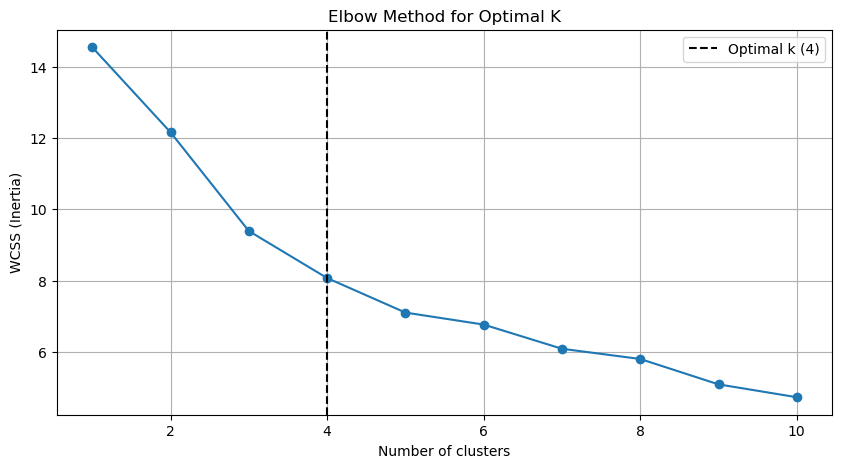

In [18]:
from sklearn.cluster import KMeans
from kneed import KneeLocator 
from sklearn.preprocessing import MinMaxScaler

# Select the variables that will be used for clustering
features = ["Purchases", "Male (%)", "Female (%)", "Digital Payments (%)", "Clothing (%)", "Accessories (%)"]
X = summary[features]

# Normalize the feature values so they are on a comparable scale
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(X)

# Determine the optimal number of clusters using the Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)

# Use KneeLocator to find the optimal K
knee_locator = KneeLocator(range(1, 11), wcss, curve="convex", direction="decreasing")
optimal_k = knee_locator.knee

# Plot the graph
plt.figure(figsize=(10, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.axvline(x=optimal_k, color='black', linestyle='--', label=f"Optimal k ({optimal_k})")
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.legend()

plt.show()

In [19]:
# Perform K-Means clustering using the selected optimal number of clusters
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42)

# Assign each observation to a cluster and store the cluster labels in the summary table
summary['Cluster'] = kmeans.fit_predict(scaled_features)

In [20]:
# Extract the locations that belong to each cluster
cluster_0 = summary[summary["Cluster"] == 0]["Location"].reset_index(drop=True)
cluster_1 = summary[summary["Cluster"] == 1]["Location"].reset_index(drop=True)
cluster_2 = summary[summary["Cluster"] == 2]["Location"].reset_index(drop=True)
cluster_3 = summary[summary["Cluster"] == 3]["Location"].reset_index(drop=True)

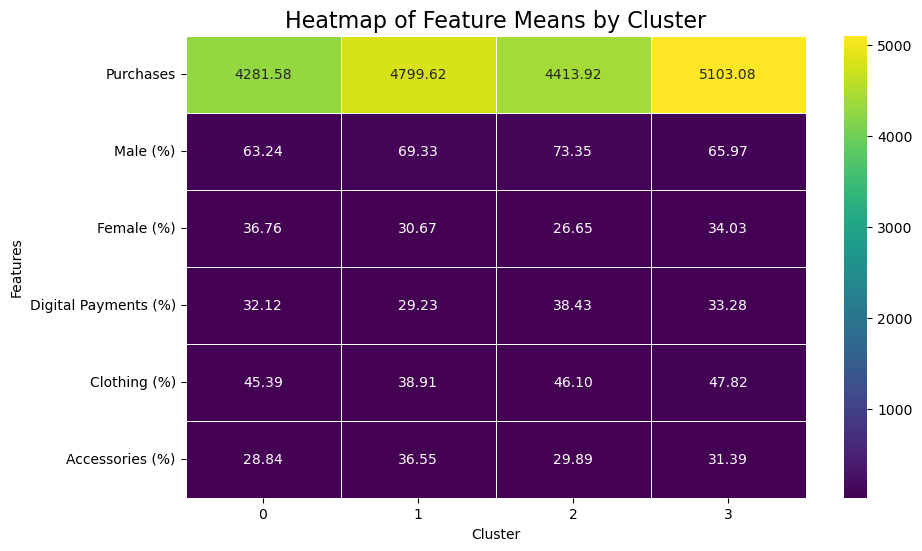

In [21]:
import seaborn as sns

# Calculate the mean value of each feature within each cluster
cluster_means = summary.groupby('Cluster')[["Purchases", "Male (%)", "Female (%)", "Digital Payments (%)", "Clothing (%)", "Accessories (%)"]].mean()

# Create a heatmap to compare average feature values across clusters
plt.figure(figsize=(10, 6))
sns.heatmap(cluster_means.T, cmap="viridis", annot=True, fmt=".2f", linewidths=0.5)
plt.title('Heatmap of Feature Means by Cluster', size=16)
plt.xlabel('Cluster')
plt.ylabel('Features')

plt.show()

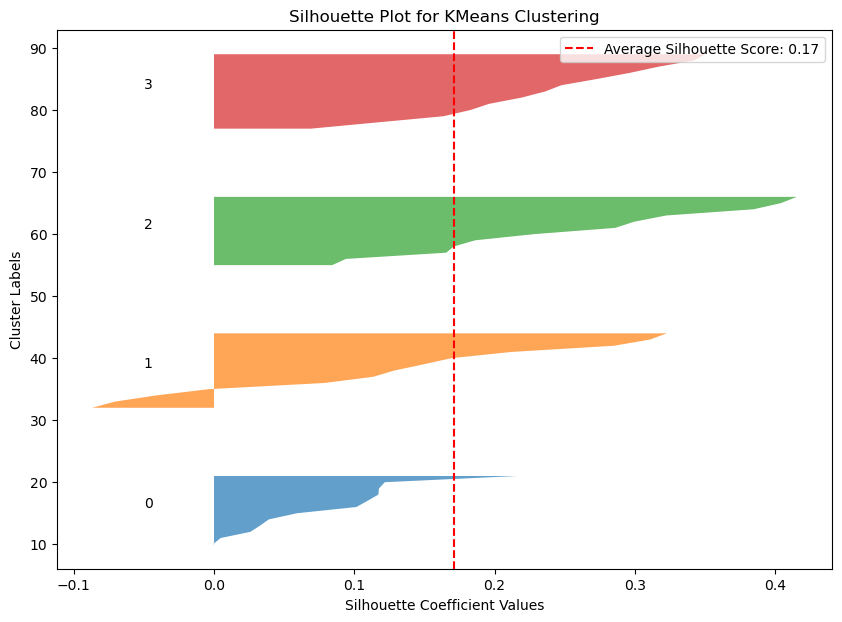

In [22]:
from sklearn.metrics import silhouette_samples, silhouette_score
import numpy as np

# Calculate the overall average silhouette score for all observations
silhouette_avg = silhouette_score(scaled_features, summary['Cluster'])

# Calculate the silhouette score for each individual observation
sample_silhouette_values = silhouette_samples(scaled_features, summary['Cluster'])

# Plot silhouette scores
plt.figure(figsize=(10, 7))
y_lower = 10
n_clusters = optimal_k

# Loop through each cluster to plot its silhouette values
for i in range(n_clusters):
    ith_cluster_silhouette_values = sample_silhouette_values[summary['Cluster'] == i]
    ith_cluster_silhouette_values.sort()

    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i

    plt.fill_betweenx(
        np.arange(y_lower, y_upper),
        0, ith_cluster_silhouette_values,
        alpha=0.7
    )

    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10

# Add title, axis labels, legend, and vertical line
plt.axvline(x=silhouette_avg, color="red", linestyle="--", label=f"Average Silhouette Score: {silhouette_avg:.2f}")
plt.title("Silhouette Plot for KMeans Clustering")
plt.xlabel("Silhouette Coefficient Values")
plt.ylabel("Cluster Labels")
plt.legend()

plt.show()

### Classification Task

In [23]:
# Import tools for model training, preprocessing, and evaluation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, RobustScaler, OrdinalEncoder
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve, auc
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Suppress warning messages for cleaner output
import warnings
warnings.filterwarnings("ignore")

# Load the dataset
df = pd.read_csv("shopping_trends.csv")

# Select the variables to be used in the classification task
selected_columns = [
    "Gender", "Discount Applied", "Promo Code Used", "Payment Method",
    "Frequency of Purchases", "Season", "Review Rating", "Previous Purchases",
    "Size", "Purchase Amount (USD)"
]
df_class = df[selected_columns].copy()

# Encode binary categorical variables using LabelEncoder
binary_cols = ["Gender", "Discount Applied", "Promo Code Used"]
for col in binary_cols:
    le = LabelEncoder()
    df_class[col] = le.fit_transform(df_class[col])

# Apply ordinal encoding to categorical variables with multiple categories
ordinal_encoder = OrdinalEncoder()
df_class[["Payment Method", "Frequency of Purchases", "Season"]] = ordinal_encoder.fit_transform(
    df_class[["Payment Method", "Frequency of Purchases", "Season"]]
)

# Convert clothing size into ordered numeric values
size_mapping = {"S": 1, "M": 2, "L": 3, "XL": 4}
df_class["Size"] = df_class["Size"].map(size_mapping)

# Create additional interaction features
df_class["Promo_Discount_Interaction"] = df_class["Promo Code Used"] * df_class["Discount Applied"]
df_class["Previous_Promo_Interaction"] = df_class["Promo Code Used"] * df_class["Previous Purchases"]
df_class["Avg_Purchase_Amount"] = df_class["Purchase Amount (USD)"] / (df_class["Previous Purchases"] + 1)

# Define predictors and binary target variable
# Target = 1 if purchase amount is above the median, otherwise 0
X = df_class.drop(columns=["Purchase Amount (USD)"])
y = df_class["Purchase Amount (USD)"].apply(lambda x: 1 if x > df_class["Purchase Amount (USD)"].median() else 0)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the predictors using RobustScaler to reduce the effect of outliers
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define hyperparameter grid for Random Forest
rf_params = {
    "n_estimators": [200, 500],
    "max_depth": [10, 20],
    "min_samples_split": [2, 5]
}

# Build the classification models
models = {
    "Random Forest": GridSearchCV(
        RandomForestClassifier(random_state=42),
        rf_params,
        cv=3,
        n_jobs=-1
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=500,
        learning_rate=0.02,
        random_state=42
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance"
    ),
    "SVM": SVC(
        probability=True,
        kernel="linear",
        C=1.5,
        class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=20,
        min_samples_split=4,
        random_state=42
    )
}

# Train each model and calculate performance metrics
results = []

for name, model in models.items():

    # Apply scaled data to models that are sensitive to feature scale
    if name in ["SVM", "K-Nearest Neighbors"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]

    # Apply GridSearchCV model separately and extract the best estimator
    elif isinstance(model, GridSearchCV):
        model.fit(X_train, y_train)
        best_model = model.best_estimator_
        y_pred = best_model.predict(X_test)
        y_prob = best_model.predict_proba(X_test)[:, 1]

    # Train the remaining models on the original training data
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

    # Compute evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)

    # Store model name and performance results
    results.append([name, accuracy, auc_score])

# Convert results into a DataFrame and rank models by accuracy
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "AUC"]).sort_values(
    by="Accuracy", ascending=False
)

results_df

,Model,Accuracy,AUC
4,Decision Tree,0.988462,0.988514
0,Random Forest,0.952564,0.993466
1,AdaBoost,0.834615,0.958067
2,K-Nearest Neighbors,0.721795,0.790728
3,SVM,0.702564,0.783823


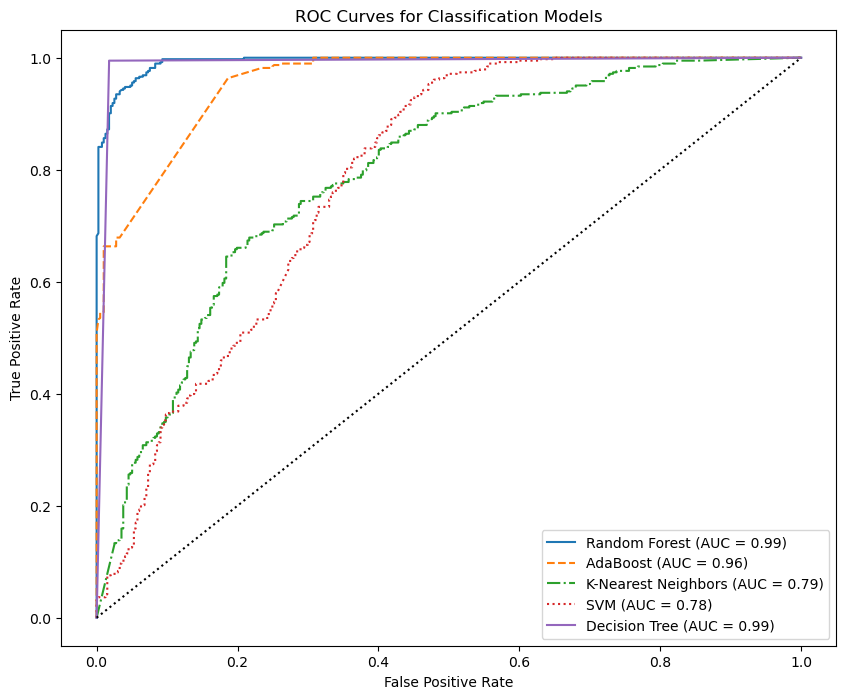

In [24]:
# Create a figure for ROC curve comparison
plt.figure(figsize=(10, 8))

# Define line styles so each model appears differently
line_styles = ["solid", "dashed", "dashdot", "dotted"]

# Plot ROC curve for each classifier
for idx, (name, model) in enumerate(models.items()):

    # Use scaled test data for scale-sensitive models
    if name in ["SVM", "K-Nearest Neighbors"]:
        y_score = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_score = model.predict_proba(X_test)[:, 1]

    # Compute false positive rate, true positive rate, and AUC
    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve for the current model
    plt.plot(
        fpr,
        tpr,
        linestyle=line_styles[idx % len(line_styles)],
        label=f"{name} (AUC = {roc_auc:.2f})"
    )

# Add diagonal reference line for random classification
plt.plot([0, 1], [0, 1], linestyle=":", color="black")

# Add axis labels, title, and legend
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Classification Models")
plt.legend(loc="lower right")

# Display the plot
plt.show()

### Regression Task

In [25]:
# Import functions for data splitting, preprocessing, model fitting, and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, PowerTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

# Load the shopping trends dataset
df = pd.read_csv("shopping_trends.csv")

# Select the variables to be used in the regression task
selected_columns = [
    "Gender", "Discount Applied", "Promo Code Used", "Payment Method",
    "Frequency of Purchases", "Season", "Review Rating", "Previous Purchases",
    "Size", "Purchase Amount (USD)"
]
df_reg = df[selected_columns].copy()

# Encode categorical variables into numeric form
categorical_columns = ["Gender", "Discount Applied", "Promo Code Used", "Payment Method", "Frequency of Purchases", "Season"]
for col in categorical_columns:
    le = LabelEncoder()
    df_reg[col] = le.fit_transform(df_reg[col])

# Convert size categories into ordered numeric values
size_mapping = {"S": 1, "M": 2, "L": 3, "XL": 4}
df_reg["Size"] = df_reg["Size"].map(size_mapping)

# Create additional interaction-based features
df_reg["Promo_Discount_Interaction"] = df_reg["Promo Code Used"] * df_reg["Discount Applied"]
df_reg["Previous_Promo_Interaction"] = df_reg["Promo Code Used"] * df_reg["Previous Purchases"]
df_reg["Avg_Purchase_Amount"] = df_reg["Purchase Amount (USD)"] / (df_reg["Previous Purchases"] + 1)

# Define predictors and target variable
X = df_reg.drop(columns=["Purchase Amount (USD)"])   # input features
y = df_reg["Purchase Amount (USD)"]                  # continuous target variable

# Apply a power transformation to stabilise the target distribution
power_transformer = PowerTransformer(method='yeo-johnson')
y_transformed = power_transformer.fit_transform(y.values.reshape(-1, 1)).flatten()

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y_transformed, test_size=0.2, random_state=42
)

# Standardise the predictors for models that are sensitive to scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the regression models to compare
regressors = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=200, learning_rate=0.05, random_state=42),
    "SVM": SVR(kernel="rbf"),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42)
}

# Train each model and evaluate predictive performance
results = []

for name, model in regressors.items():

    # Use scaled data for models affected by feature magnitude
    if name in ["Linear Regression", "SVM", "Ridge Regression", "Lasso Regression", "ElasticNet"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)

    # Use unscaled data for tree-based ensemble models
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

    # Calculate regression evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    # Store model performance results
    results.append([name, mae, rmse, r2])

# Convert results to a DataFrame and sort by R-squared
results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R²"]).sort_values(
    by='R²', ascending=False
)

results_df

,Model,MAE,RMSE,R²
1,Random Forest,0.031237,0.042926,0.998162
4,Decision Tree,0.093193,0.137494,0.981140
3,SVM,0.272545,0.379645,0.856210
2,AdaBoost,0.472281,0.584585,0.659067
0,Linear Regression,0.805154,0.934772,0.128266


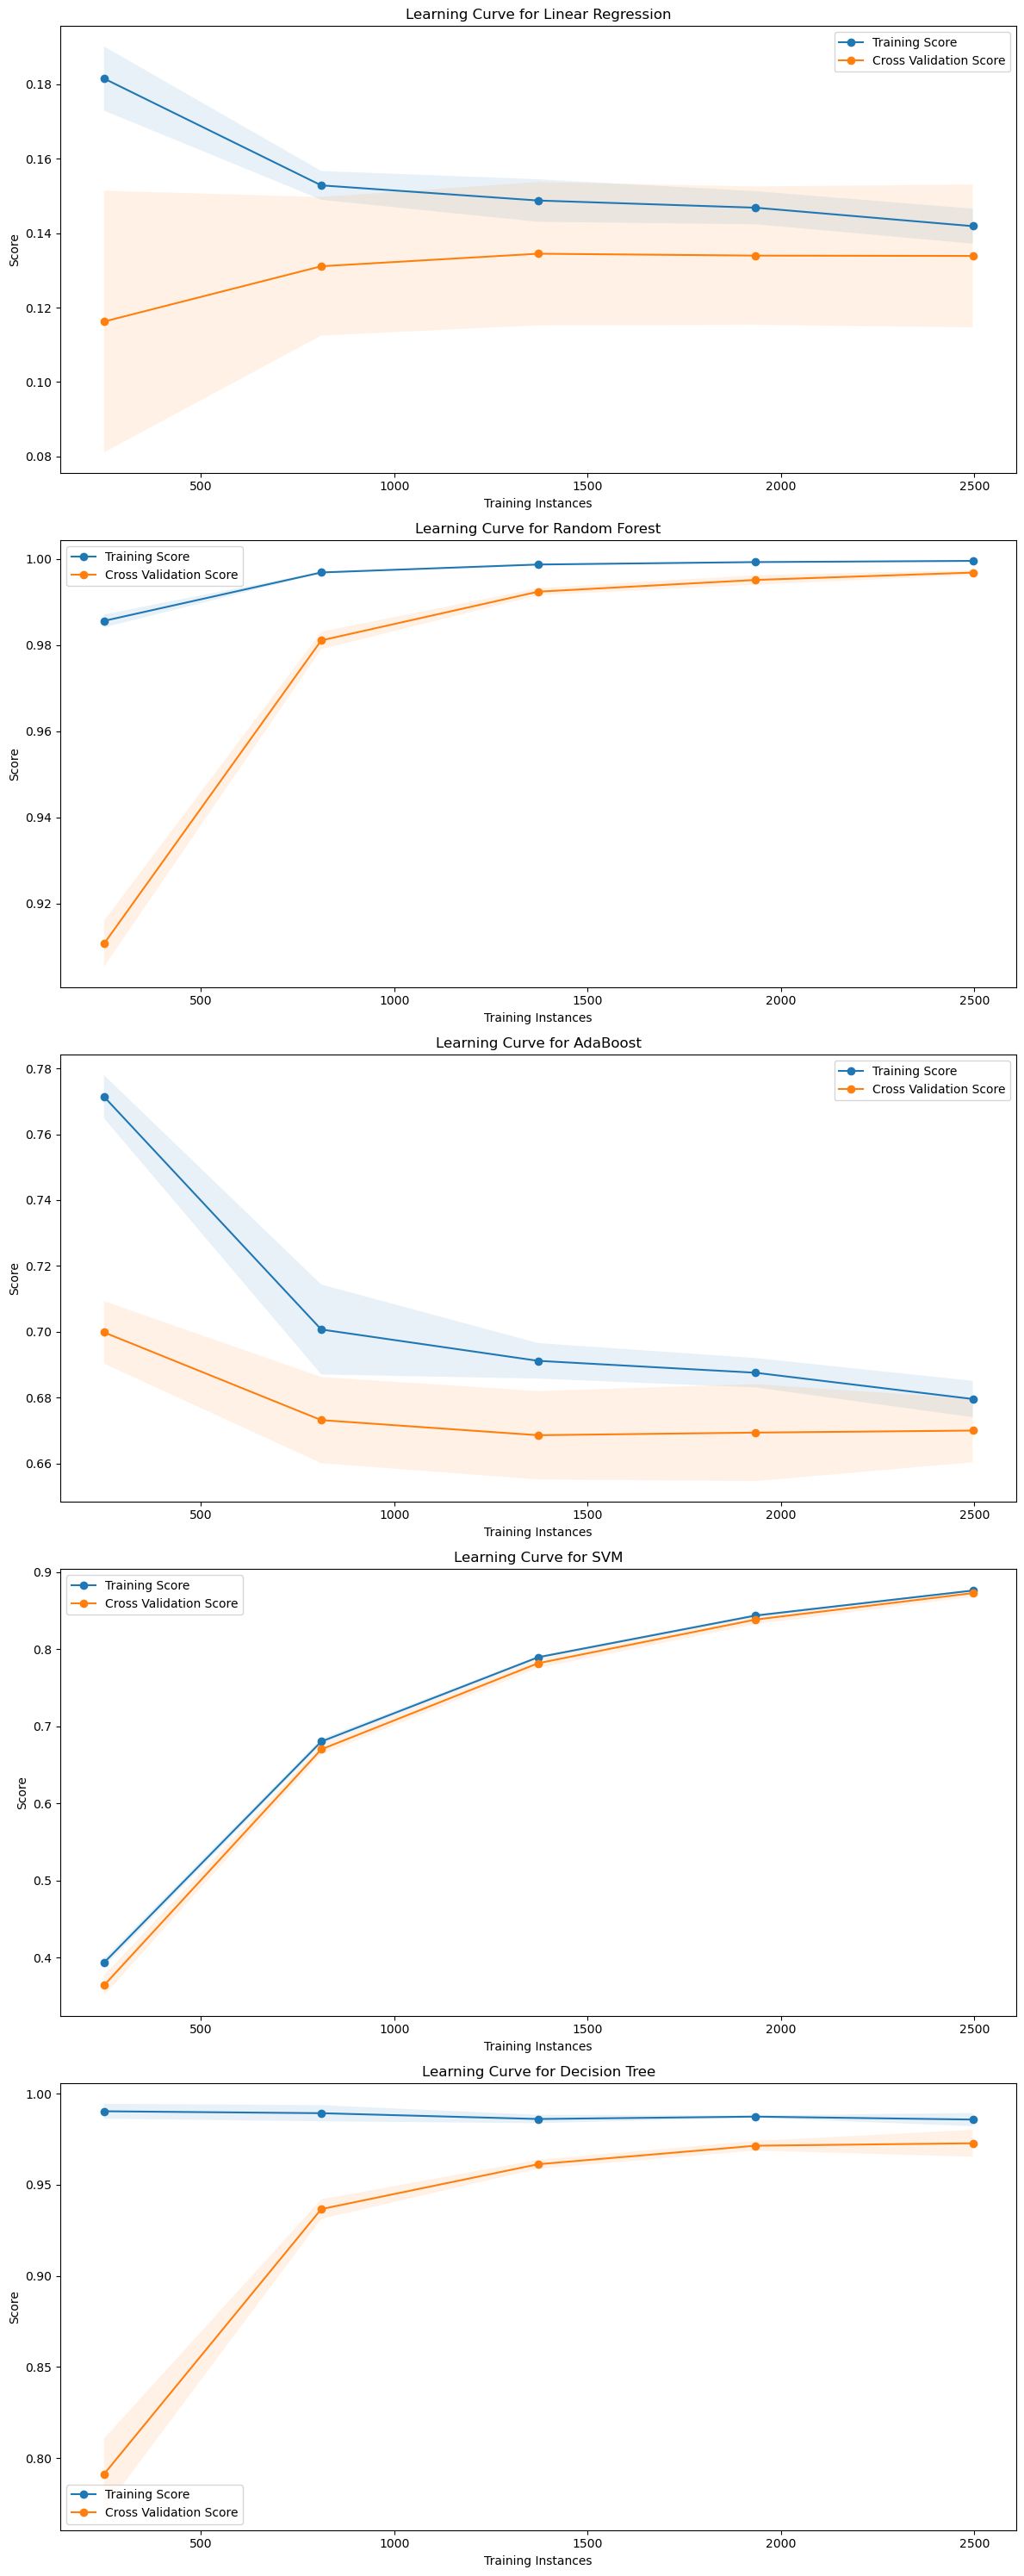

In [26]:
# Import learning curve function
from sklearn.model_selection import learning_curve

# Create one subplot for each regression model
fig, axes = plt.subplots(5, 1, figsize=(12, 30))

# Generate learning curves for all regression models
for idx, (name, model) in enumerate(regressors.items()):

    # Compute training and cross-validation scores for increasing training sizes
    train_sizes, train_scores, test_scores = learning_curve(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2",
        train_sizes=np.linspace(0.1, 1.0, 5),
        n_jobs=-1
    )

    # Calculate average training and validation scores
    train_scores_mean = np.mean(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)

    # Plot the average training score
    axes[idx].plot(train_sizes, train_scores_mean, 'o-', label="Training Score")

    # Plot the average cross-validation score
    axes[idx].plot(train_sizes, test_scores_mean, 'o-', label="Cross Validation Score")

    # Add shaded areas to show score variability
    axes[idx].fill_between(
        train_sizes,
        train_scores_mean - train_scores.std(axis=1),
        train_scores_mean + train_scores.std(axis=1),
        alpha=0.1
    )

    axes[idx].fill_between(
        train_sizes,
        test_scores_mean - test_scores.std(axis=1),
        test_scores_mean + test_scores.std(axis=1),
        alpha=0.1
    )

    # Add axis labels, title, and legend
    axes[idx].set_xlabel("Training Instances")
    axes[idx].set_ylabel("Score")
    axes[idx].set_title(f"Learning Curve for {name}")
    axes[idx].legend(loc="best")

# Adjust layout and display the figure
plt.tight_layout()
plt.show()